# 04. Projeção 2027 e Simulador de Cenários de Crescimento

**Etapa CRISP-DM:** Entrega Executiva / Deployment (*Forecast Cascata 2027*)

### Como funciona o motor de projeção recursivo em cascata
Partindo do último mês fechado real (`2026-10`, carteira de **33.755** clientes):
1. Projeta os meses-ponte de encerramento de 2026 (`2026-11` e `2026-12`) igualmente em todos os cenários, garantindo partida idêntica em **01/01/2027** (`35.645` clientes).
2. Para cada mês de **Jan/2027 a Dez/2027**, combina o **calendário real de dias úteis ponderados (`1 / 0,5 / 0`)** com as alavancas de expansão (novos bairros ativos/mês e novos canais comerciais) em três cenários:
   - **Conservador**: manutenção da malha atual com expansão mínima de bairros (`+1/mês`), sem novos canais.
   - **Base**: continuidade orgânica de 2026 com expansão moderada de bairros (`+4/mês`).
   - **Expansão**: abertura acelerada de novos bairros (`+9/mês`) + entrada de **1 novo canal comercial** a partir de Mar/2027.
3. Acopla **Vendas -> Carteira Ativa & Safras Recentes (3m) -> Retiradas -> Saldo Líquido -> Nova Carteira** mês a mês, com **Intervalo de Predição de 90%**.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path("..").resolve()
DATA_PROC = ROOT / "data" / "processed"
DATA_PRED = ROOT / "data" / "predictions"
FIG_DIR = ROOT / "reports" / "figures"

sns.set_theme(style="whitegrid")

df_hist = pd.read_parquet(DATA_PROC / "serie_mensal_ml.parquet")
df_closed = df_hist[df_hist["mes_fechado"]].copy()
df_pred = pd.read_parquet(DATA_PRED / "projecao_2027.parquet")
with open(DATA_PRED / "resumo_2027.json", encoding="utf-8") as f:
    resumo = json.load(f)

print("=== QUADRO EXECUTIVO COMPARATIVO — CENÁRIOS 2027 ===")
df_resumo = pd.DataFrame(resumo["cenarios_2027"]).T
cols_show = [
    "vendas_total_2027", "vendas_media_mensal_2027",
    "retiradas_total_2027", "retiradas_media_mensal_2027",
    "saldo_liquido_2027", "carteira_inicio_2027", "carteira_fim_2027",
    "crescimento_carteira_2027_pct", "churn_medio_mensal_sobre_carteira_pct",
    "relacao_retirada_venda_2027_pct",
]
display(df_resumo[cols_show])


=== QUADRO EXECUTIVO COMPARATIVO — CENÁRIOS 2027 ===


,vendas_total_2027,vendas_media_mensal_2027,retiradas_total_2027,retiradas_media_mensal_2027,saldo_liquido_2027,carteira_inicio_2027,carteira_fim_2027,crescimento_carteira_2027_pct,churn_medio_mensal_sobre_carteira_pct,relacao_retirada_venda_2027_pct
Conservador,21377.0,1781.4,13977.0,1164.7,7400.0,35645.0,43045.0,20.76,2.97,65.38
Base,24430.0,2035.8,13917.0,1159.8,10513.0,35645.0,46157.0,29.49,2.86,56.97
Expansao,31106.0,2592.1,15008.0,1250.7,16098.0,35645.0,51742.0,45.16,2.91,48.25


## 1. Projeção Mensal Detalhada de 2027 — Cenário Base

Observe como a ponderação de dias úteis (`1 / 0,5 / 0`) se reflete com naturalidade ao longo de 2027: meses mais curtos ou com feriados (como **Fev/2027** com `20,0 DU` no Carnaval e **Mai/2027** com `21,0 DU`) projetam volumes proporcionais à capacidade útil real, enquanto meses longos (**Mar, Jun, Ago, Dez**) concentram maior volume.

In [2]:
base_2027 = df_pred[(df_pred["cenario"] == "Base") & (df_pred["ano"] == 2027)].copy()
display(base_2027[[
    "anomes", "dias_uteis_ponderados", "qtd_bairros_ativos_proj",
    "vendas_prev", "vendas_ic_inf", "vendas_ic_sup",
    "retiradas_prev", "saldo_liquido_prev", "carteira_fim_mes_prev",
    "taxa_churn_carteira_pct", "relacao_retirada_venda_pct"
]].reset_index(drop=True))


,anomes,dias_uteis_ponderados,qtd_bairros_ativos_proj,vendas_prev,vendas_ic_inf,vendas_ic_sup,retiradas_prev,saldo_liquido_prev,carteira_fim_mes_prev,taxa_churn_carteira_pct,relacao_retirada_venda_pct
0,2027-01,22.5,311.7,1961.1,1801.5,2120.6,997.3,963.8,36608.4,2.80,50.85
1,2027-02,20.0,315.7,1747.1,1582.1,1912.0,1002.9,744.2,37352.6,2.74,57.40
2,2027-03,24.0,319.7,2088.1,1917.9,2258.3,1041.4,1046.7,38399.3,2.79,49.87
3,2027-04,23.0,323.7,1987.3,1812.0,2162.6,1075.2,912.1,39311.4,2.80,54.10
4,2027-05,21.0,327.7,1805.0,1624.7,1985.2,1102.8,702.2,40013.6,2.81,61.10
5,2027-06,24.0,331.7,2064.2,1879.2,2249.2,1154.8,909.4,40923.0,2.89,55.94
6,2027-07,23.5,335.7,2040.2,1850.5,2229.9,1191.2,848.9,41771.9,2.91,58.39
7,2027-08,24.0,339.7,2121.8,1927.5,2316.1,1226.3,895.5,42667.4,2.94,57.80
8,2027-09,23.0,343.7,2084.2,1885.4,2282.9,1261.5,822.6,43490.0,2.96,60.53
9,2027-10,22.5,347.7,2094.8,1891.7,2297.9,1277.7,817.0,44307.1,2.94,61.00


## 2. Gráficos Executivos — Trajetória 2024–2027 (Vendas, Retiradas e Crescimento de Carteira)

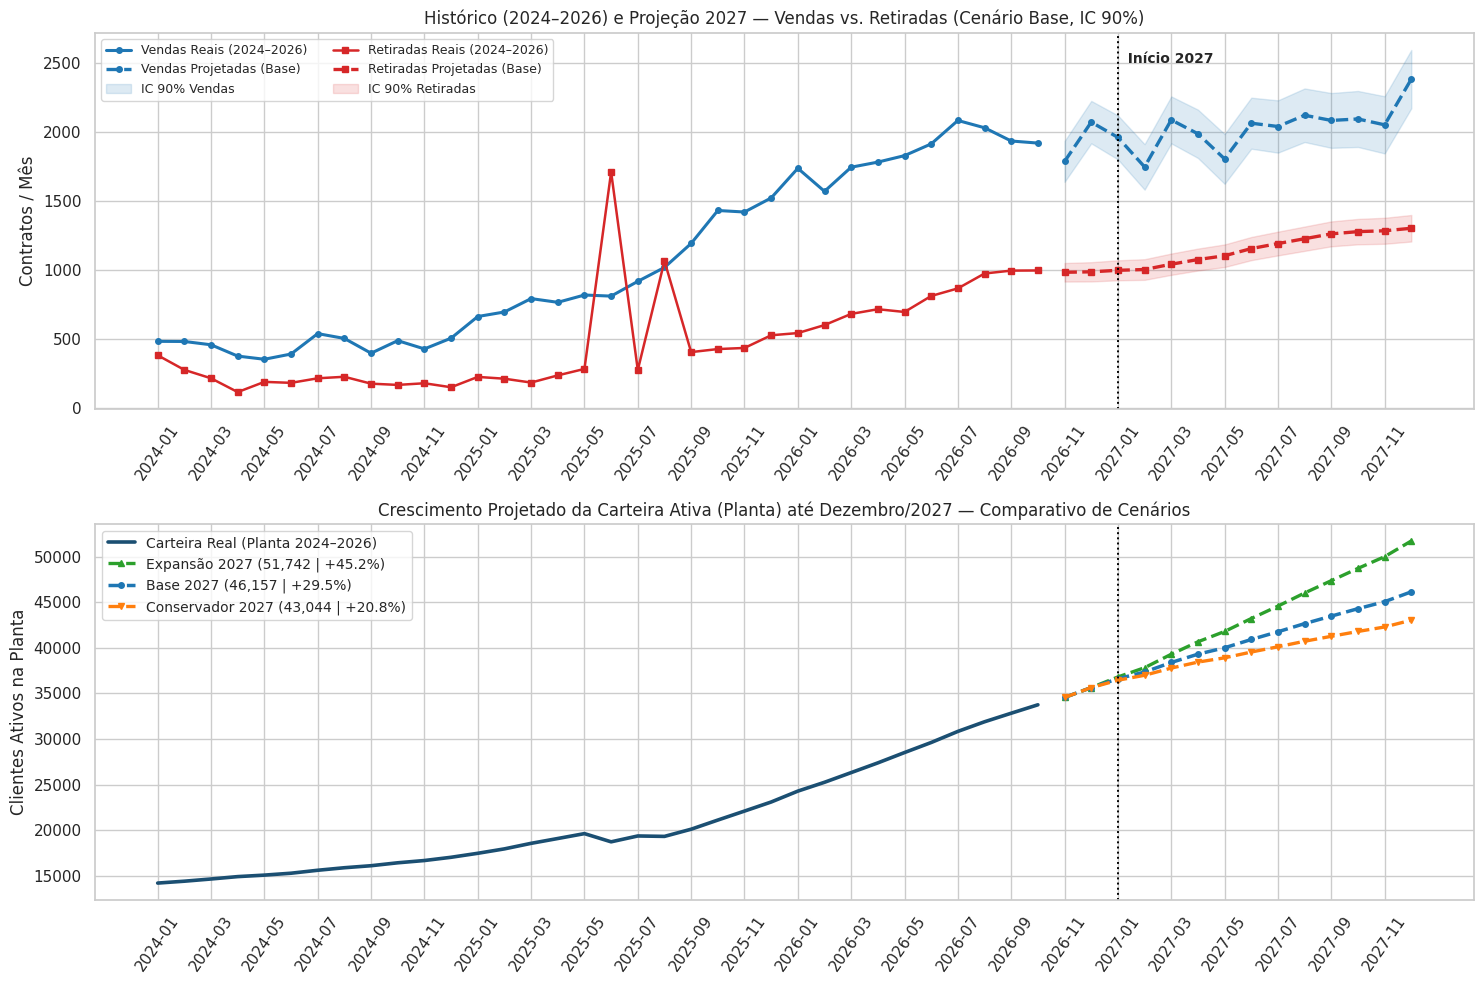

In [3]:
base_full = df_pred[df_pred["cenario"] == "Base"].copy()
cons_full = df_pred[df_pred["cenario"] == "Conservador"].copy()
exp_full = df_pred[df_pred["cenario"] == "Expansao"].copy()

fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Painel 1: Histórico + Projeção Base de Vendas e Retiradas com IC 90%
ax = axes[0]
ax.plot(df_closed["anomes"], df_closed["vendas"], color="#1f77b4", lw=2.2, marker="o", markersize=4, label="Vendas Reais (2024–2026)")
ax.plot(base_full["anomes"], base_full["vendas_prev"], color="#1f77b4", lw=2.4, ls="--", marker="o", markersize=4, label="Vendas Projetadas (Base)")
ax.fill_between(base_full["anomes"], base_full["vendas_ic_inf"], base_full["vendas_ic_sup"], color="#1f77b4", alpha=0.15, label="IC 90% Vendas")

ax.plot(df_closed["anomes"], df_closed["retiradas"], color="#d62728", lw=1.8, marker="s", markersize=4, label="Retiradas Reais (2024–2026)")
ax.plot(base_full["anomes"], base_full["retiradas_prev"], color="#d62728", lw=2.4, ls="--", marker="s", markersize=4, label="Retiradas Projetadas (Base)")
ax.fill_between(base_full["anomes"], base_full["retiradas_ic_inf"], base_full["retiradas_ic_sup"], color="#d62728", alpha=0.14, label="IC 90% Retiradas")

ax.axvline("2027-01", color="black", ls=":", lw=1.4)
ax.text("2027-01", ax.get_ylim()[1] * 0.92, "  Início 2027", fontweight="bold", fontsize=10)
ax.set_title("Histórico (2024–2026) e Projeção 2027 — Vendas vs. Retiradas (Cenário Base, IC 90%)")
ax.set_ylabel("Contratos / Mês")
ax.tick_params(axis="x", rotation=55)
ticks_all = list(df_closed["anomes"]) + list(base_full["anomes"])
ax.set_xticks(ticks_all[::2])
ax.legend(loc="upper left", ncol=2, fontsize=9)

# Painel 2: Curva de Crescimento da Carteira (Planta) nos 3 cenários
ax2 = axes[1]
ax2.plot(df_closed["anomes"], df_closed["carteira_fim_mes"], color="#1b4f72", lw=2.6, label="Carteira Real (Planta 2024–2026)")
ax2.plot(exp_full["anomes"], exp_full["carteira_fim_mes_prev"], color="#2ca02c", lw=2.4, ls="--", marker="^", markersize=4,
         label=f"Expansão 2027 ({int(exp_full.iloc[-1]['carteira_fim_mes_prev']):,} | +{resumo['cenarios_2027']['Expansao']['crescimento_carteira_2027_pct']:.1f}%)")
ax2.plot(base_full["anomes"], base_full["carteira_fim_mes_prev"], color="#1f77b4", lw=2.5, ls="--", marker="o", markersize=4,
         label=f"Base 2027 ({int(base_full.iloc[-1]['carteira_fim_mes_prev']):,} | +{resumo['cenarios_2027']['Base']['crescimento_carteira_2027_pct']:.1f}%)")
ax2.plot(cons_full["anomes"], cons_full["carteira_fim_mes_prev"], color="#ff7f0e", lw=2.4, ls="--", marker="v", markersize=4,
         label=f"Conservador 2027 ({int(cons_full.iloc[-1]['carteira_fim_mes_prev']):,} | +{resumo['cenarios_2027']['Conservador']['crescimento_carteira_2027_pct']:.1f}%)")

ax2.axvline("2027-01", color="black", ls=":", lw=1.4)
ax2.set_title("Crescimento Projetado da Carteira Ativa (Planta) até Dezembro/2027 — Comparativo de Cenários")
ax2.set_ylabel("Clientes Ativos na Planta")
ax2.tick_params(axis="x", rotation=55)
ax2.set_xticks(ticks_all[::2])
ax2.legend(loc="upper left", fontsize=10)

plt.tight_layout()
plt.savefig(FIG_DIR / "04_projecao_2027_cenarios_carteira.png", dpi=140)
plt.show()


## 3. Saldo Líquido Mensal de 2027 e Comparativo Histórico Anual (2024–2027)

,Periodo,Vendas,Retiradas,Saldo_Liquido
0,2024 (Real),5393.0,2460.0,2933.0
1,2025 (Real),12042.0,5974.0,6068.0
2,2026 (Real+Ponte),22406.0,9844.0,12562.0
3,2027 (Conserv.),21377.0,13977.0,7400.0
4,2027 (Base),24430.0,13917.0,10513.0
5,2027 (Expansão),31106.0,15008.0,16098.0


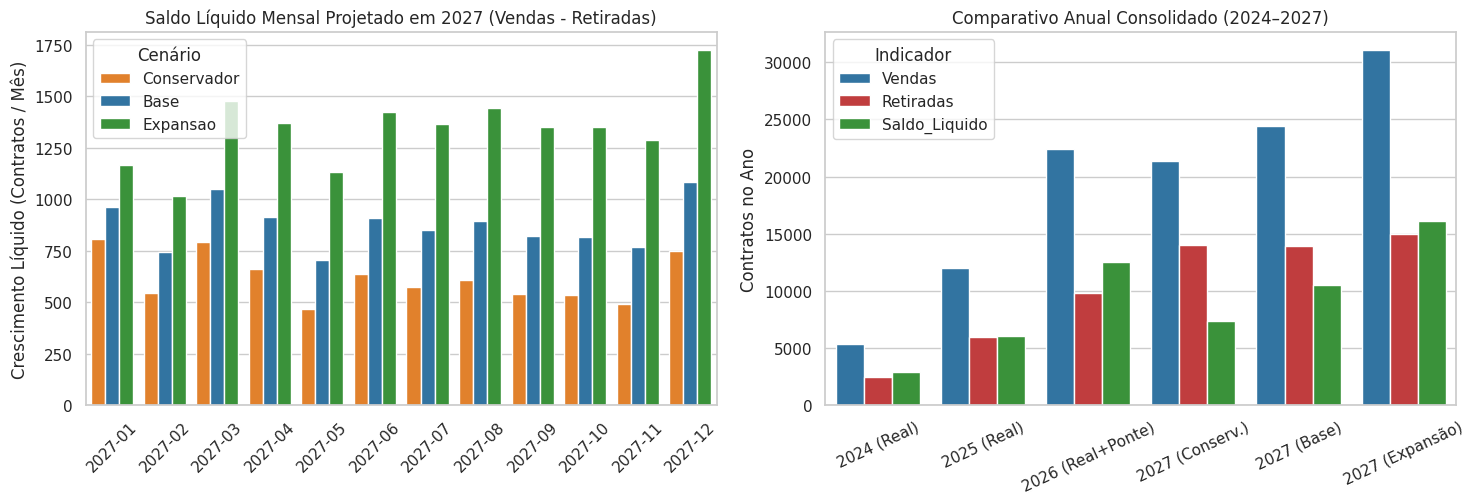

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

# Saldo líquido mensal 2027 nos 3 cenários
df_2027_all = df_pred[df_pred["ano"] == 2027].copy()
sns.barplot(data=df_2027_all, x="anomes", y="saldo_liquido_prev", hue="cenario",
            palette={"Conservador": "#ff7f0e", "Base": "#1f77b4", "Expansao": "#2ca02c"}, ax=axes[0])
axes[0].set_title("Saldo Líquido Mensal Projetado em 2027 (Vendas - Retiradas)")
axes[0].set_xlabel("")
axes[0].set_ylabel("Crescimento Líquido (Contratos / Mês)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(title="Cenário")

# Evolução Anual Consolidada: 2024 Real, 2025 Real, 2026 Real+Ponte, 2027 Base
hist_anual = df_closed.groupby("ano", as_index=False).agg(vendas=("vendas", "sum"), retiradas=("retiradas", "sum"))
ponte_2026 = base_full[base_full["ano"] == 2026]
v_2026_full = float(hist_anual.loc[hist_anual["ano"] == 2026, "vendas"].iloc[0] + ponte_2026["vendas_prev"].sum())
r_2026_full = float(hist_anual.loc[hist_anual["ano"] == 2026, "retiradas"].iloc[0] + ponte_2026["retiradas_prev"].sum())

df_comp = pd.DataFrame([
    {"Periodo": "2024 (Real)", "Vendas": float(hist_anual.loc[hist_anual["ano"] == 2024, "vendas"].iloc[0]), "Retiradas": float(hist_anual.loc[hist_anual["ano"] == 2024, "retiradas"].iloc[0])},
    {"Periodo": "2025 (Real)", "Vendas": float(hist_anual.loc[hist_anual["ano"] == 2025, "vendas"].iloc[0]), "Retiradas": float(hist_anual.loc[hist_anual["ano"] == 2025, "retiradas"].iloc[0])},
    {"Periodo": "2026 (Real+Ponte)", "Vendas": round(v_2026_full, 0), "Retiradas": round(r_2026_full, 0)},
    {"Periodo": "2027 (Conserv.)", "Vendas": resumo["cenarios_2027"]["Conservador"]["vendas_total_2027"], "Retiradas": resumo["cenarios_2027"]["Conservador"]["retiradas_total_2027"]},
    {"Periodo": "2027 (Base)", "Vendas": resumo["cenarios_2027"]["Base"]["vendas_total_2027"], "Retiradas": resumo["cenarios_2027"]["Base"]["retiradas_total_2027"]},
    {"Periodo": "2027 (Expansão)", "Vendas": resumo["cenarios_2027"]["Expansao"]["vendas_total_2027"], "Retiradas": resumo["cenarios_2027"]["Expansao"]["retiradas_total_2027"]},
])
df_comp["Saldo_Liquido"] = df_comp["Vendas"] - df_comp["Retiradas"]
display(df_comp)

df_comp_m = df_comp.melt(id_vars="Periodo", value_vars=["Vendas", "Retiradas", "Saldo_Liquido"], var_name="Indicador", value_name="Contratos")
sns.barplot(data=df_comp_m, x="Periodo", y="Contratos", hue="Indicador",
            palette={"Vendas": "#1f77b4", "Retiradas": "#d62728", "Saldo_Liquido": "#2ca02c"}, ax=axes[1])
axes[1].set_title("Comparativo Anual Consolidado (2024–2027)")
axes[1].set_xlabel("")
axes[1].set_ylabel("Contratos no Ano")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig(FIG_DIR / "04_saldo_liquido_e_comparativo_anual.png", dpi=140)
plt.show()


### Conclusões Executivas & Próximos Passos de MLOps
1. **Crescimento consistente em 2027**: no cenário **Base**, a empresa projeta **24.430 vendas** contra **13.917 retiradas**, gerando **+10.513 clientes líquidos** e elevando a planta de **35.645** para **46.157 clientes (+29,5%)**.
2. **Impacto real de Novos Bairros e Novos Canais**: no cenário **Expansão** (priorizando abertura de bairros de **Rede Própria** — que a EDA mostrou entregar ~9 vendas/mês no M6 — somado a 1 novo canal comercial qualificado), a carteira pode alcançar **51.742 clientes (+45,2%)** com relação retirada/venda caindo para **48,3%**.
3. **Rotina MLOps recomendada**:
   - Re-executar `python -m src.pipeline --step all` todo início de mês após o fechamento do mês anterior no Airflow;
   - Monitorar o erro mensal (`MAPE`) real vs. previsto em `models/metadata.json` para detectar *drift* comercial ou de inadimplência;
   - Opcionalmente, expor `data/predictions/projecao_2027.json` em uma nova aba **"Projeção 2027"** dentro do `dash-retencao`.